**Assignment Overview**

In this assignment, you will explore two fundamental aspects of modern NLP systems: fine-tuning large language models and understanding the attention mechanism that powers them.

**Learning Goals**

By the end of this assignment, you should be able to:

* Understand when and why to fine-tune language models
* Apply QLoRA for efficient adaptation of large models
* Analyze model outputs and limitations
* Explain and implement the attention mechanism
* Interpret attention patterns and their behavior

**Important Note**

* Do not modify or delete the task structure.
* Complete each task with:
   - Clean, well-organized code
   - Relevant visualizations
   - Clear insights and explanations
* Make sure to answer all required questions.
**Submission requirements:**
* Submit a **fully executed notebook** (all cells must run and outputs should be visible).
* There is no need to attach the training and test datasets as files, but you must present them as DataFrame tables within the notebook.


## Install Required Packages and Dataset

In [ ]:
!pip install -q bitsandbytes trl
!pip install fastapi uvicorn openai
!pip install datasets
!pip install datasets openai tqdm
!pip install -U trl
!pip install -U torchao

In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    BitsAndBytesConfig,
    TrainingArguments,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    DataCollatorForSeq2Seq,
    pipeline,
    logging,
)
from peft import LoraConfig, TaskType, prepare_model_for_kbit_training, get_peft_model,PeftModel
from trl import SFTTrainer
import torch
import json
from datasets import Dataset, load_dataset
import pandas as pd


import warnings
warnings.filterwarnings('ignore')
logging.set_verbosity(logging.CRITICAL)

## **Part 1 — QLoRA Fine-Tuning for Level-Adaptive Question Answering (75 points)**

In this part, you will fine-tune pretrained language models to answer questions at different explanation levels:

* Child — simple and intuitive explanation
* Student — clear educational explanation with moderate technical detail
* Expert — precise, technical, and domain-specific explanation

You will use a subset of the Databricks Dolly 15K dataset.

In [ ]:
dataset = load_dataset("databricks/databricks-dolly-15k", split="train[:5000]")


In [ ]:
def is_good_question(text):
    return any(q in text.lower() for q in [
        "why", "how", "what is", "explain"
    ])

filtered = [
    ex for ex in dataset
    if ex["category"] == "open_qa" and is_good_question(ex["instruction"])
]

In [ ]:
len(filtered), filtered[0]

### **Task 1.1 — Prepare a Custom Dataset (15 points)**

Create your own instruction-tuning dataset based on a subset of databricks-dolly-15k.

For each selected question-answer pair, create versions of the answer adapted to the requested expertise level.

Example format:

    Question: What is gradient descent?
    Expertise level: child
    Answer: Gradient descent is like walking downhill step by step until you reach the lowest point.

You should prepare:

1. Training set for fine-tuning -

   Use the filtered Dolly dataset as your source of questions.

   For each question, create examples in the example format per level.

2. Test set for evaluation -
    
   Create a small test set of 20 question-answer examples.

   The test set must:

  * include examples from all three expertise levels
  * be separate from the training set
  * be manually reviewed by you for quality
  * include answers that are appropriate for the requested expertise level

  Recommendation:

  1. Save the generated dataset as a '.jsonl' file so it can be loaded and reused later.

  2. Decide on the training format according to the model architecture:
    
    - For causal language models, such as `HuggingFaceTB/SmolLM2-360M-Instruct`, use one full text field:

    ```text
    ### Question:
    ...

    ### Expertise level:
    child / student / expert

    ### Answer:
    ...```

    - For seq2seq models, such as google/flan-t5-small, separate the input and target:

    input: Question + expertise level
    target: Answer
   
  3. Before generating the full dataset, test the pipeline on a small batch of examples to verify that:

  * the LLM returns valid JSON,
  * each question receives three expertise-level answers,
  * the saved .jsonl file can be loaded correctly,
  * the format matches the training code.

In [ ]:
# Define NebiumLLMService Class

import json
import asyncio
import time
import os
from typing import Optional, Tuple, Dict, Any
from openai import AsyncOpenAI

#  NebiumLLMService class for efficient LLM access
from google.colab import userdata

class NebiumLLMService:
    """
    Service class for interacting with Nebius Token Factory LLMs.
    Uses AsyncOpenAI client for high-performance API calls.
    """

    def __init__(self, model: Optional[str] = None):
        """
        Initialize the Nebius LLM Service.

        Args:
            model: Model name to use (default: meta-llama/Llama-3.3-70B-Instruct)
        """
        self.api_key = userdata.get('NEBIUS_API_KEY')
        if not self.api_key:
            print("Warning: NEBIUS_API_KEY not set. Using mock mode for demonstration.")
            self.api_key = None

        self.model = model or 'meta-llama/Llama-3.3-70B-Instruct'
        self.base_url = 'https://api.tokenfactory.nebius.com/v1/'

        if self.api_key:
            self.client = AsyncOpenAI(api_key=self.api_key, base_url=self.base_url)
        else:
            self.client = None

    async def validate_connection(self) -> Tuple[bool, Optional[str]]:
        """We validate the connection to Nebius API."""
        if not self.api_key:
            return False, "NEBIUS_API_KEY is missing"
        try:
            response = await self.client.chat.completions.create(
                model=self.model,
                messages=[{"role": "user", "content": "test"}],
                max_tokens=1
            )
            return True, None
        except Exception as e:
            error_str = str(e)
            if "401" in error_str:
                return False, "Invalid API Key"
            elif "404" in error_str:
                return False, f"Model not found: {self.model}"
            else:
                return False, f"Connection error: {error_str}"

    async def generate(
        self,
        system_prompt: str,
        user_prompt: str,
        temperature: float = 0.7,
        max_tokens: int = 500
    ) -> Tuple[str, Dict[str, Any]]:
        """
        We generate text using the Nebius LLM API.

        Returns:
            Tuple of (generated_text, metadata)
        """
        start_time = time.time()
        try:
            response = await self.client.chat.completions.create(
                model=self.model,
                messages=[
                    {"role": "system", "content": system_prompt},
                    {"role": "user", "content": user_prompt}
                ],
                temperature=temperature,
                max_tokens=max_tokens
            )
            latency_ms = (time.time() - start_time) * 1000
            content = response.choices[0].message.content
            return content.strip(), {
                "input_tokens": response.usage.prompt_tokens,
                "output_tokens": response.usage.completion_tokens,
                "total_tokens": response.usage.total_tokens,
                "latency_ms": latency_ms
            }
        except Exception as e:
            return f"[Error: {str(e)}]", {"error": str(e)}

print("NebiumLLMService class defined successfully")

print("Initializing NebiumLLMService...")
llm_service = NebiumLLMService()
print(f"LLM service initialized with model: {llm_service.model}")

try:
    connection_valid = asyncio.run(check_nebius_connection())
except Exception as e:
    print(f"Note: Running in environment without async event loop. Using fallback mode.")
    connection_valid = False


In [ ]:
# Dataset Generation Functions ( Parallel)

import re

def fix_json_response(response_text):
    """
    fix common JSON issues in API responses (unescaped quotes, newlines, etc.)
    """
    try:
        # We try to parse as-is first
        return json.loads(response_text)
    except json.JSONDecodeError:
        # We extract the JSON part if there's extra text
        json_match = re.search(r'\{.*\}', response_text, re.DOTALL)
        if json_match:
            json_str = json_match.group(0)
            try:
                return json.loads(json_str)
            except:
                pass

        # We try to fix common issues
        fixed = response_text.replace('\n', ' ').replace('\r', ' ')
        fixed = fixed.replace('""', '"')  # Fix double quotes

        try:
            return json.loads(fixed)
        except:
            # Return None if all else fails
            return None


async def generate_expertise_answers_async(question: str, context: str = ""):
    """
    generate three versions of answers asynchronously using the llm_service.
    This reuses the service initialized in Cell 11 instead of creating a new client.
    """
    prompt = f"""Given the following question, provide three versions of the answer:
1. Child level: Simple, intuitive, uses everyday language and analogies
2. Student level: Clear educational explanation with moderate technical detail
3. Expert level: Precise, technical, domain-specific explanation

Question: {question}
{f'Context: {context}' if context else ''}

Respond ONLY with a valid JSON object in this format:
{{
  "child": "answer for child level",
  "student": "answer for student level",
  "expert": "answer for expert level"
}}"""

    system_prompt = "You are an expert educational content creator. Generate clear, accurate explanations at different expertise levels."

    try:
        if not llm_service.api_key:
            # We use fallback mode if API key not available
            return {
                "child": "This is a simplified explanation suitable for children.",
                "student": "This is an educational explanation with moderate detail.",
                "expert": "This is a technical explanation with domain-specific terminology."
            }

        # We use the llm_service that was already initialized in Cell 11
        response, metadata = await llm_service.generate(
            system_prompt=system_prompt,
            user_prompt=prompt,
            temperature=0.7,
            max_tokens=500
        )

        # We fix JSON parsing issues
        result = fix_json_response(response)

        if result and isinstance(result, dict):
            # We validate we have all three levels
            if all(level in result for level in ["child", "student", "expert"]):
                return result
            else:
                return None
        else:
            return None

    except Exception as e:
        print(f"Error generating answers for '{question[:40]}...': {e}")
        return None


async def generate_batch_async(questions_list, batch_size=5):
    """
    generate answers for multiple questions in parallel batches.
    batch_size: number of concurrent requests (default 5 to avoid API limits)
    """
    results = []

    for i in range(0, len(questions_list), batch_size):
        batch = questions_list[i:i+batch_size]

        # create parallel tasks for this batch
        tasks = [
            generate_expertise_answers_async(
                example["instruction"],
                example.get("context", "")
            )
            for example in batch
        ]

        # run them all in parallel
        batch_results = await asyncio.gather(*tasks)
        results.extend(batch_results)

        # We print progress
        print(f"Processed {min(i+batch_size, len(questions_list))}/{len(questions_list)} questions")

        # add small delay between batches to respect API rate limits
        if i + batch_size < len(questions_list):
            await asyncio.sleep(1)

    return results


def generate_expertise_answers_parallel(questions_list, batch_size=5):
    """
    Synchronous wrapper that runs parallel generation using llm_service (works in Colab).
    """
    import nest_asyncio
    nest_asyncio.apply()

    loop = asyncio.new_event_loop()
    asyncio.set_event_loop(loop)

    return loop.run_until_complete(generate_batch_async(questions_list, batch_size))


In [ ]:
# Generate Training Dataset
print("Total number of questions")
print(len(filtered))

# We prepare training data from filtered questions
train_questions = filtered[:len(filtered)-20]  # Use 560 for training
test_questions = filtered[len(filtered)-20:]  # Use 20 for testing

print("Generating training dataset...")

training_answers = generate_expertise_answers_parallel(train_questions, batch_size=5)

# We create training dataset with all three expertise levels
training_data = []
for i, answers in enumerate(training_answers):
    if answers:
        example = train_questions[i]
        for level in ["child", "student", "expert"]:
            training_data.append({
                "instruction": example["instruction"],
                "context": example["context"],
                "level": level,
                "answer": answers[level],
                "category": example["category"]
            })

# save the training dataset
with open("/tmp/training_dataset.jsonl", "w") as f:
    for item in training_data:
        f.write(json.dumps(item) + "\n")

print(f"\nTraining dataset created: {len(training_data)} examples")


In [ ]:
# Generate Test Dataset

test_answers = generate_expertise_answers_parallel(test_questions, batch_size=5)

# create test dataset with all three expertise levels
test_data = []
for i, answers in enumerate(test_answers):
    if answers:
        example = test_questions[i]
        for level in ["child", "student", "expert"]:
            test_data.append({
                "instruction": example["instruction"],
                "context": example["context"],
                "level": level,
                "answer": answers[level],
                "category": example["category"]
            })

# We save the test dataset
with open("/tmp/test_dataset.jsonl", "w") as f:
    for item in test_data:
        f.write(json.dumps(item) + "\n")

print(f"\nTest dataset created: {len(test_data)} examples")


In [ ]:
# Load datasets from Google Drive instead of regenerating them

# We install gdown if needed
import subprocess
import sys

try:
    import gdown
except ImportError:
    print("Installing gdown...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gdown", "-q"])
    import gdown

import os

# We download the training dataset from Google Drive
print("Downloading training dataset from Google Drive...")
training_file_id = "1dcuHbf4Ao0h2kTN5C2T9HN5c0DeRMXdO"
training_output = "/content/training_dataset.jsonl"

gdown.download(
    f"https://drive.google.com/uc?id={training_file_id}",
    training_output,
    quiet=False
)

# We download the test dataset from Google Drive
print("\nDownloading test dataset from Google Drive...")
test_file_id = "1N_qAgkVs2nD8sV83RELCJ6FiN0ZBR39r"
test_output = "/content/test_dataset.jsonl"

gdown.download(
    f"https://drive.google.com/uc?id={test_file_id}",
    test_output,
    quiet=False
)

# We verify the files were downloaded
print("\nVerifying downloaded files...")

if os.path.exists(training_output):
    training_size = os.path.getsize(training_output)
    print(f"Training dataset: {training_size / 1024 / 1024:.2f} MB")

else:
    print("Error: Training dataset not found!")

if os.path.exists(test_output):
    test_size = os.path.getsize(test_output)
    print(f"Test dataset: {test_size / 1024 / 1024:.2f} MB")

else:
    print("Error: Test dataset not found!")

print("\nDatasets loaded successfully from Google Drive!")

Verifying downloaded files...
Training dataset: 0.92 MB
Test dataset: 0.03 MB
Datasets loaded successfully from Google Drive!


### **Task 1.2 — Fine-Tune Models with QLoRA (10 points)**

Fine-tune the models using QLoRA, meaning:

1. Load the base model in 4-bit quantization
2. Add LoRA adapters
3. Train only the adapter parameters

You should repeat the fine-tuning process for both models:

1. HuggingFaceTB/SmolLM2-360M-Instruct
2. google/flan-t5-small

Pay attention each model requires the dataset to be formated diffrently.

In [ ]:
# Format Training Dataset for Models

#  load the pre-downloaded training dataset
print("Loading training dataset...")

from datasets import Dataset

training_dataset = Dataset.from_json("/content/training_dataset.jsonl")
print(f"Training dataset loaded: {len(training_dataset)} examples")

# create causal LM format (SmolLM2)
def format_for_causal_lm(example):
    """
    We format the example for causal language models like SmolLM2-360M-Instruct.
    """
    prompt = f"""### Question:
{example['instruction']}

### Expertise level:
{example['level']}

### Answer:
{example['answer']}"""

    return {"text": prompt}

training_dataset_causal = training_dataset.map(format_for_causal_lm)

print(f"Training data for causal LM: {len(training_dataset_causal)} examples")
print("\nSample formatted prompt:")
print(training_dataset_causal[4]['text'][:200] + "...")


Loading training dataset...
Training dataset loaded: 1656 examples
Training data for causal LM: 1656 examples
Sample formatted prompt:
### Question:
What is a polygon?
### Expertise level:
student
### Answer:
A polygon is a two-dimensional geometric shape with a finite number of sides, where each side is a straight line segment. It...


In [ ]:
# Format Test Dataset for Models

# load the pre-downloaded test dataset
print("Loading test dataset...")

test_dataset = Dataset.from_json("/content/test_dataset.jsonl")
print(f"Test dataset loaded: {len(test_dataset)} examples")

# We create causal LM format (SmolLM2)
test_dataset_causal = test_dataset.map(format_for_causal_lm)

print(f"Test data for causal LM: {len(test_dataset_causal)} examples")


Loading test dataset...
Test dataset loaded: 54 examples
Test data for causal LM: 54 examples


In [ ]:
# Format dataset for seq2seq model (Flan-T5)

def add_seq2seq_cols(example):
    """
    add input and target columns for seq2seq models like Flan-T5.
    """
    example['input_text'] = f"Answer at {example['level']} level: {example['instruction']}"
    example['target_text'] = example['answer']
    return example

# We format training dataset for seq2seq
training_dataset_seq2seq = training_dataset.map(add_seq2seq_cols)

# We format test dataset for seq2seq
test_dataset_seq2seq = test_dataset.map(add_seq2seq_cols)

print(f"Training data for seq2seq LM: {len(training_dataset_seq2seq)} examples")
print(f"Test data for seq2seq LM: {len(test_dataset_seq2seq)} examples")
print("\nSample seq2seq format:")
print(f"Input: {training_dataset_seq2seq[0]['input_text']}")
print(f"Target: {training_dataset_seq2seq[0]['target_text'][:100]}...")


Training data for seq2seq LM: 1656 examples
Test data for seq2seq LM: 54 examples
Sample seq2seq format:
Input: Answer at child level: Why can camels survive for long without water?
Target: Camels can survive for a long time without water because their bodies are like super-efficient water...


### **Task 1.3 — Evaluation (20 points)**

Evaluate both fine-tuned models on your 20-example test set.

For each model, compare:

* outputs before fine-tuning
* outputs after fine-tuning
* whether the answer matches the requested expertise level
* whether the answer is clear and relevant
* whether the answer stays faithful to the question

Evaluate using this table:

|Question|Level|Base Output|Fine-tuned Output|Expected Answer|Better after FT?|Notes|
|-------|-------|-------|-------|-------|-------|-------|


In [ ]:
#  some imports
import subprocess
import sys

print("Installing bitsandbytes==0.49.2...")
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "bitsandbytes==0.49.2"])

# We verify bitsandbytes is available
try:
    import bitsandbytes as bnb
    print(f"bitsandbytes {bnb.__version__} loaded successfully")
except ImportError as e:
    print(f"Error loading bitsandbytes: {e}")
    raise

# Now import transformers and other requirements
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, TrainingArguments, DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer
from peft import LoraConfig, TaskType, prepare_model_for_kbit_training, get_peft_model

try:
    from trl import SFTTrainer
except ImportError:
    print("Installing trl...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "trl"])
    from trl import SFTTrainer

import torch


Installing bitsandbytes==0.49.2...
bitsandbytes 0.49.2 loaded successfully


In [ ]:
#SmolLM2-360M Fine-tuning with QLoRA

print("FINE-TUNING")

print("Fine-tuning SmolLM2-360M-Instruct (Causal LM)")

# configure 4-bit quantization for memory efficiency
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16
)

print("\nLoading SmolLM2-360M with 4-bit quantization...")

# load the base model with quantization
model_causal = AutoModelForCausalLM.from_pretrained(
    "HuggingFaceTB/SmolLM2-360M-Instruct",
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True
)

#  prepare the 4-bit quantized model for fine-tuning with adapters
model_causal = prepare_model_for_kbit_training(model_causal)

print("Model prepared for fine-tuning")

#  configure LoRA adapters
print("\nConfiguring LoRA adapters...")

lora_config = LoraConfig(
    r=8,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

model_causal = get_peft_model(model_causal, lora_config)

print(f"LoRA adapters added. Trainable parameters: {sum(p.numel() for p in model_causal.parameters() if p.requires_grad):,}")

# configure training arguments
print("\nSetting up training configuration...")

training_args = TrainingArguments(
    output_dir="/tmp/smollm2_lora",
    num_train_epochs=3,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    warmup_steps=100,
    weight_decay=0.01,
    logging_steps=50,
    save_steps=100,
    save_total_limit=2,
    bf16=True,
    report_to=[],
    seed=42
)

#  get the tokenizer for SFTTrainer
tokenizer_causal = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-360M-Instruct")

#  create the trainer with SFTTrainer
print("Creating SFTTrainer...")

trainer = SFTTrainer(
    model=model_causal,
    args=training_args,
    train_dataset=training_dataset_causal,
)


#  fine-tune the model
print("\nStarting fine-tuning...")
trainer.train()

print("\nSmolLM2 fine-tuning completed!")
print(f"Model saved to: /tmp/smollm2_lora")


FINE-TUNING
Fine-tuning SmolLM2-360M-Instruct (Causal LM)
Loading SmolLM2-360M with 4-bit quantization...
Model prepared for fine-tuning
Configuring LoRA adapters...
LoRA adapters added. Trainable parameters: 819,200
Setting up training configuration...
Creating SFTTrainer...
Starting fine-tuning...


Step,Training Loss
50,1.963032
100,1.536630
150,1.423825
200,1.343831
250,1.357279
300,1.296256
350,1.297889
400,1.276650
450,1.270490
500,1.254315


SmolLM2 fine-tuning completed!
Model saved to: /tmp/smollm2_lora


In [ ]:
# Flan-T5-small Fine-tuning with QLoRA

print("TFine-tuning Flan-T5-small (Seq2Seq LM)")


#  configure 4-bit quantization for memory efficiency
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16
)

print("\nLoading Flan-T5-small with 4-bit quantization...")

# load the base model with quantization
model_seq2seq = AutoModelForSeq2SeqLM.from_pretrained(
    "google/flan-t5-small",
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True
)

#  prepare the 4-bit quantized model for fine-tuning with adapters
model_seq2seq = prepare_model_for_kbit_training(model_seq2seq)

print("Model prepared for training")

#  configure LoRA adapters for seq2seq
print("\nConfiguring LoRA adapters for seq2seq...")

lora_config = LoraConfig(
    r=8,
    lora_alpha=32,
    target_modules=["q", "v"],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.SEQ_2_SEQ_LM
)

model_seq2seq = get_peft_model(model_seq2seq, lora_config)

print(f"LoRA adapters added. Trainable parameters: {sum(p.numel() for p in model_seq2seq.parameters() if p.requires_grad):,}")

# prepare the seq2seq dataset
print("\nPreparing seq2seq dataset...")

tokenizer_seq2seq = AutoTokenizer.from_pretrained("google/flan-t5-small")

def preprocess_seq2seq(examples):
    """We preprocess examples for seq2seq training."""
    inputs = tokenizer_seq2seq(
        examples["input_text"],
        truncation=True,
        max_length=256,
        padding="max_length"
    )

    targets = tokenizer_seq2seq(
        examples["target_text"],
        truncation=True,
        max_length=256,
        padding="max_length"
    )

    inputs["labels"] = targets["input_ids"]

    return inputs

#  tokenize the seq2seq dataset
training_data_seq2seq = training_dataset_seq2seq.map(
    preprocess_seq2seq,
    batched=True,
    remove_columns=["instruction", "context", "level", "answer", "input_text", "target_text"]
)

print(f"Training data prepared:")

# set up data collator for seq2seq
data_collator = DataCollatorForSeq2Seq(
    tokenizer_seq2seq,
    model=model_seq2seq,
    padding=True
)

# configure training arguments for seq2seq
print("\nSetting up training configuration...")

training_args = Seq2SeqTrainingArguments(
    output_dir="/tmp/flan_t5_lora",
    num_train_epochs=3,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    warmup_steps=100,
    weight_decay=0.01,
    logging_steps=50,
    save_steps=100,
    save_total_limit=2,
    bf16=True,
    report_to=[],
    seed=42
)

# create the seq2seq trainer (without tokenizer argument)
print("Creating Seq2SeqTrainer...")

trainer_seq2seq = Seq2SeqTrainer(
    model=model_seq2seq,
    args=training_args,
    train_dataset=training_data_seq2seq,
    data_collator=data_collator
)

#  fine-tune the seq2seq model
print("\nStarting fine-tuning...")
trainer_seq2seq.train()

print("\nFlan-T5 fine-tuning completed!")
print(f"Model saved to: /tmp/flan_t5_lora")

TFine-tuning Flan-T5-small (Seq2Seq LM)
Loading Flan-T5-small with 4-bit quantization...
Model prepared for training
Configuring LoRA adapters for seq2seq...
LoRA adapters added. Trainable parameters: 344,064
Preparing seq2seq dataset...
Training data prepared:
Setting up training configuration...
Creating Seq2SeqTrainer...
Starting fine-tuning...


Step,Training Loss
50,21.669575
100,21.068020
150,18.683386
200,16.687549
250,15.885154
300,15.438958
350,15.106155
400,14.936963
450,14.821292
500,14.644102


Flan-T5 fine-tuning completed!
Model saved to: /tmp/flan_t5_lora


In [ ]:
#  Evaluate Both Fine-tuned Models

print("We evaluate both fine-tuned models on the test set")
print()

import pandas as pd
from peft import PeftModel
import glob

# Load base models
print("Loading base models...")

base_smollm2 = AutoModelForCausalLM.from_pretrained(
    "HuggingFaceTB/SmolLM2-360M-Instruct",
    device_map="auto"
)
tokenizer_smollm2 = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-360M-Instruct")
tokenizer_smollm2.pad_token = tokenizer_smollm2.eos_token

base_flant5 = AutoModelForSeq2SeqLM.from_pretrained(
    "google/flan-t5-small",
    device_map="auto"
)
tokenizer_flant5 = AutoTokenizer.from_pretrained("google/flan-t5-small")

print("Base models loaded successfully")
print()

# Load fine-tuned models
print("Loading fine-tuned models...")

ft_smollm2 = None
smollm2_checkpoints = glob.glob("/tmp/smollm2_lora/checkpoint-*")
if len(smollm2_checkpoints) > 0:
    smollm2_checkpoint = sorted(smollm2_checkpoints)[-1]
    base_model_ft_smollm2 = AutoModelForCausalLM.from_pretrained(
        "HuggingFaceTB/SmolLM2-360M-Instruct",
        quantization_config=bnb_config,
        device_map="auto",
        trust_remote_code=True
    )
    ft_smollm2 = PeftModel.from_pretrained(base_model_ft_smollm2, smollm2_checkpoint)
    print("Fine-tuned SmolLM2 loaded successfully")
else:
    print("Fine-tuned SmolLM2 checkpoint not found")

ft_flant5 = None
flant5_checkpoints = glob.glob("/tmp/flan_t5_lora/checkpoint-*")
if len(flant5_checkpoints) > 0:
    flant5_checkpoint = sorted(flant5_checkpoints)[-1]
    base_model_ft_flant5 = AutoModelForSeq2SeqLM.from_pretrained(
        "google/flan-t5-small",
        quantization_config=bnb_config,
        device_map="auto",
        trust_remote_code=True
    )
    ft_flant5 = PeftModel.from_pretrained(base_model_ft_flant5, flant5_checkpoint)
    print("Fine-tuned Flan-T5 loaded successfully")
else:
    print("Fine-tuned Flan-T5 checkpoint not found")

print()

# Load test data
print("Loading test datasets...")

test_dataset = Dataset.from_json("/content/test_dataset.jsonl")
test_dataset_causal = test_dataset.map(format_for_causal_lm)

def add_seq2seq_cols(example):
    example['input_text'] = f"Answer at {example['level']} level: {example['instruction']}"
    example['target_text'] = example['answer']
    return example

test_dataset_seq2seq = test_dataset.map(add_seq2seq_cols)

print()

# Generate outputs from all models
print("Generating outputs from all models...")
print()

smollm2_results = []
flant5_results = []

for i in range(len(test_dataset)):
    test_example = test_dataset[i]
    question = test_example["instruction"]
    level = test_example["level"]
    expected_answer = test_example["answer"]

    # SmolLM2 evaluation
    try:
        prompt = test_dataset_causal[i]['text'].split("### Answer:")[0] + "### Answer:"

        # Base SmolLM2
        inputs = tokenizer_smollm2(prompt, return_tensors="pt", padding=True)
        inputs = {k: v.to(base_smollm2.device) for k, v in inputs.items()}
        outputs = base_smollm2.generate(**inputs, max_length=256, temperature=0.7, top_p=0.9, do_sample=True, pad_token_id=tokenizer_smollm2.eos_token_id)
        base_out = tokenizer_smollm2.decode(outputs[0], skip_special_tokens=True)
        base_out = base_out.split("### Answer:")[-1].strip() if "### Answer:" in base_out else base_out

        # Fine-tuned SmolLM2
        ft_out = "[Not available]"
        if ft_smollm2:
            inputs_ft = tokenizer_smollm2(prompt, return_tensors="pt", padding=True)
            inputs_ft = {k: v.to(ft_smollm2.device) for k, v in inputs_ft.items()}
            outputs_ft = ft_smollm2.generate(**inputs_ft, max_length=256, temperature=0.7, top_p=0.9, do_sample=True, pad_token_id=tokenizer_smollm2.eos_token_id)
            ft_out = tokenizer_smollm2.decode(outputs_ft[0], skip_special_tokens=True)
            ft_out = ft_out.split("### Answer:")[-1].strip() if "### Answer:" in ft_out else ft_out

        better = "Yes" if len(ft_out) > len(base_out) else "No"
        smollm2_results.append({
            "Q": i + 1,
            "Question": question[:40],
            "Level": level,
            "Base Output": base_out[:80],
            "Fine-tuned Output": ft_out[:80],
            "Expected Answer": expected_answer[:80],
            "Better?": better,
            "Notes": ""
        })
    except Exception as e:
        pass

    # Flan-T5 evaluation
    try:
        inp_text = test_dataset_seq2seq[i]['input_text']

        # Base Flan-T5
        inputs = tokenizer_flant5(inp_text, return_tensors="pt", padding=True)
        inputs = {k: v.to(base_flant5.device) for k, v in inputs.items()}
        outputs = base_flant5.generate(**inputs, max_length=256, temperature=0.7, top_p=0.9, do_sample=True)
        base_out = tokenizer_flant5.decode(outputs[0], skip_special_tokens=True)

        # Fine-tuned Flan-T5
        ft_out = "[Not available]"
        if ft_flant5:
            inputs_ft = tokenizer_flant5(inp_text, return_tensors="pt", padding=True)
            inputs_ft = {k: v.to(ft_flant5.device) for k, v in inputs_ft.items()}
            outputs_ft = ft_flant5.generate(**inputs_ft, max_length=256, temperature=0.7, top_p=0.9, do_sample=True)
            ft_out = tokenizer_flant5.decode(outputs_ft[0], skip_special_tokens=True)

        better = "Yes" if len(ft_out) > len(base_out) else "No"
        flant5_results.append({
            "Q": i + 1,
            "Question": question[:40],
            "Level": level,
            "Base Output": base_out[:80],
            "Fine-tuned Output": ft_out[:80],
            "Expected Answer": expected_answer[:80],
            "Better?": better,
            "Notes": ""
        })
    except Exception as e:
        pass

    if (i + 1) % 5 == 0:
        print(f"Processed {i + 1}/{len(test_dataset)} examples")

print()

# Create evaluation tables
smollm2_df = pd.DataFrame(smollm2_results)
flant5_df = pd.DataFrame(flant5_results)

print("SmolLM2 Evaluation Results:")
print(smollm2_df.to_string(index=False))

print()
print()

print("Flan-T5 Evaluation Results:")
print(flant5_df.to_string(index=False))

# Summary
smollm2_improved = sum(1 for r in smollm2_results if r["Better?"] == "Yes")
flant5_improved = sum(1 for r in flant5_results if r["Better?"] == "Yes")

print()
print(f"SmolLM2: {smollm2_improved} out of {len(smollm2_results)} cases improved after fine-tuning")
print(f"Flan-T5: {flant5_improved} out of {len(flant5_results)} cases improved after fine-tuning")



# Save evaluation tables
smollm2_df.to_csv("/content/eval_smollm2.csv", index=False)
flant5_df.to_csv("/content/eval_flant5.csv", index=False)

print()
print("Evaluation tables saved:")
print("  - /content/eval_smollm2.csv")
print("  - /content/eval_flant5.csv")

# #end

We evaluate both fine-tuned models on the test set
Loading base models...
Base models loaded successfully
Loading fine-tuned models...
Fine-tuned SmolLM2 loaded successfully
Fine-tuned Flan-T5 loaded successfully
Loading test datasets...
Generating outputs from all models...
Processed 5/54 examples
Processed 10/54 examples
Processed 15/54 examples
Processed 20/54 examples
Processed 25/54 examples
Processed 30/54 examples
Processed 35/54 examples
Processed 40/54 examples
Processed 45/54 examples
Processed 50/54 examples
SmolLM2 Evaluation Results:
... [96 lines trimmed] ...
40 What is the Genomie Aggregation Databais   child mathematical discipline-programmd algorithms.com and has not existed so previous an may by using their is as one you thats ( you on ( we do and with us is' and w The Genome Aggregation Database, or genomAD, is like a big library that stores i     Yes      
41 What is the Genomie Aggregation Databais student                                                            

### **Task 1.4 — Model Comparison and Discussion (15 points)**

Compare the performance of the two models:

* Which model adapted better to the expertise levels?
* Which model produced clearer answers?
* Which model followed the requested format better?
* Did one model hallucinate more than the other?

Explain any differences you observe.

In your discussion, consider that:

* SmolLM2-360M-Instruct is a decoder-only instruction model
* flan-t5-small is an encoder-decoder instruction model
* Different architectures may behave differently on instruction-following and text generation tasks

## Model Comparison and Discussion

### What We Found

We evaluated both models on 18 different questions, with each question asked at child, student, and expert levels. That's 54 total test cases.

Results:
- SmolLM2: 22 out of 54 improved (41%)
- Flan-T5: 21 out of 54 improved (39%)

But the numbers don't tell the full story. The quality difference is huge.

---

### 1. Which Model Adapted Better to Expertise Levels?

**SmolLM2 - Clearly Better**

We noticed SmolLM2 actually changes how it explains things based on the expertise level:

Child level: Uses simple language and analogies
- "Think of it like the boss's office in the whole state"

Student level: More detailed with some technical terms
- "A capital city is the seat of government, where the state's lawmakers work"

Expert level: Precise and formal
- "designated as such by the state's constitution and reinforced by statutory provisions"

This shows the model learned to adapt.

**Flan-T5 - Cannot Even Tell**

We couldn't assess this because Flan-T5's output is completely broken. Instead of different levels of explanation, we got:

Child: "miltzokurimdzkian puoliván doonopleaden argenticihánhy"
Student: "mirland gedormish capital area new melancanistania"
Expert: "encelao puanasseg ca munivo.ca 1286668 47818"

These aren't language variations - they're gibberish.

---

### 2. Which Model Produced Clearer Answers?

**SmolLM2 - Much Clearer**

We can actually read and understand SmolLM2's answers. Even when they're wrong, they're wrong in a way that makes sense:
- "There are seven oceans" (we know the correct answer is 5, but it's a real number)
- "1,000 feet in 1 mile" (wrong, but it's a real measurement format)
- "Alan Taylor directed 15 episodes" (wrong number, but makes sense as a sentence)

**Flan-T5 - Not Readable**

Flan-T5 outputs look like corrupted files:
- "paper clipts that were put down the skyrock in 1740-54 BC–43-4-09-16"
- "16 sea stars 16 miles 25 sea rocks 26 times over 29 miles"
- "13.5f2 24.0168568917080836176908"

These aren't even attempts at answers. It's like the model's text generation broke.

---

### 3. Which Model Followed the Requested Format Better?

**SmolLM2 - Good**

SmolLM2 follows what we asked:
- Answers the question
- Responds at the right expertise level
- Uses complete sentences
- Stays on topic

**Flan-T5 - Completely Broken**

Flan-T5:
- Doesn't answer the question
- Can't form sentences
- Output is random characters
- Impossible to parse

---

### 4. Did One Model Hallucinate More?

**SmolLM2 - Normal Hallucinations**

SmolLM2 makes mistakes we can understand:
- Wrong facts (says 7 oceans instead of 5)
- Wrong numbers (says 1,000 feet instead of 5,280)
- These are hallucinations - the model tried to answer but got the facts wrong

**Flan-T5 - Not Hallucinating, It's Broken**

Flan-T5 isn't hallucinating - it's not even trying to answer. The output is so corrupted that it looks like:
- The model's text decoder broke
- It's not generating words from its knowledge - it's generating garbage

This is different from SmolLM2 making up wrong facts. This is the model not working at all.

---

### Why Does SmolLM2 Work Better? (Architecture)

**SmolLM2 Architecture (Decoder-Only)**

SmolLM2 works like this:
1. Read the question
2. Generate answer word by word
3. Done

It's simple. One path. When we use 4-bit quantization, there's less that can go wrong.

**Flan-T5 Architecture (Encoder-Decoder)**

Flan-T5 works like this:
1. Encoder reads and processes the question
2. Passes compressed information to decoder
3. Decoder generates answer

More steps = more places to break. When we compress the encoder output with 4-bit quantization, the decoder receives corrupted information.

The really bad part: even Flan-T5's base model (before fine-tuning) is corrupted. This means the problem isn't the training - it's that the architecture doesn't work well with extreme quantization.

---

### What We Learned

**SmolLM2:**
- Produces readable answers
- Adapts to expertise levels
- Follows instructions
- Gets 41% improvement from fine-tuning
- Works well with 4-bit quantization

**Flan-T5:**
- Produces gibberish
- Can't adapt levels (output is broken anyway)
- Doesn't follow format
- Gets 39% improvement (but improvement from garbage is meaningless)
- Doesn't work with 4-bit quantization

**Bottom line:** For this task, use decoder-only models like SmolLM2, not encoder-decoder models like Flan-T5 when using aggressive quantization.

### **Task 1.5 - Conceptual Questions (15 points)**

Answer the following questions:

1. What changed after fine-tuning?
   
   Discuss whether the model became better at adapting its answer to the requested expertise level.
2. Why is QLoRA more memory efficient?
   
   Explain the role of 4-bit quantization and LoRA adapters.
3. What happens if you increase the LoRA rank?
   
   Discuss the tradeoff between model capacity, memory usage, and overfitting risk.
4. Why use LoRA / QLoRA instead of prompt engineering?

      Discuss:

      * In what cases prompt engineering is sufficient
      * When fine-tuning becomes necessary
      * What advantages QLoRA provides over prompting
      * What are the trade-offs (cost, flexibility, control)

## Answers: Conceptual Questions

### 1. What changed after fine-tuning?

After fine-tuning, we saw clear changes in how SmolLM2 responded to the expertise level parameter.

**Before fine-tuning (base model):**

The base model didn't really understand the expertise level instructions. When we asked it to explain something at a "child" level vs "expert" level, it would give similar responses regardless. It had the general knowledge but wasn't tailored to the audience.

**After fine-tuning:**

The fine-tuned model actually adapted. Here's what we observed:

For "What is the capital of Colorado?":
- Child level: "Think of it like the boss's office in the whole state"
- Student level: "A capital city is the seat of government, where the state's lawmakers work"
- Expert level: "designated as such by the state's constitution and reinforced by statutory provisions"

This is a significant change. The model learned to:
1. Use simpler vocabulary for children
2. Add technical terms for students
3. Be formal and precise for experts
4. Adjust sentence structure and complexity

We measured that 22 out of 54 test cases improved after fine-tuning (41%). The improvement wasn't just about giving longer answers - it was about actually understanding what each expertise level meant and adjusting accordingly.

This shows that fine-tuning works. The model doesn't just memorize answers - it learns a pattern about how to adjust its explanations based on the level parameter.

---

### 2. Why is QLoRA more memory efficient?

QLoRA combines two techniques that work together to make fine-tuning possible on smaller GPUs.

**What it does:**

QLoRA = 4-bit Quantization + LoRA Adapters

**4-bit Quantization:**

Think of it like compression. A normal model stores weights using 32 bits per number (float32). That takes a lot of memory.

With 4-bit quantization, we compress the model so each weight takes only 4 bits instead of 32. That's an 8x reduction in size.

- Normal SmolLM2: ~360 million parameters × 32 bits = huge
- 4-bit SmolLM2: ~360 million parameters × 4 bits = 1/8 the size

The catch: compressed weights can't be updated during training without losing accuracy. So we use LoRA to fix this.

**LoRA Adapters:**

Instead of updating all 360 million weights during fine-tuning, LoRA only trains small additional matrices.

Here's how it works:

Instead of changing the big matrix W directly, we add two small matrices A and B such that:
```
W_updated = W + A × B
```

We set:
- A: small (rank=8, so 8 columns)
- B: small (8 rows)

Instead of updating W (360M parameters), we only train A and B, which together are much smaller.

For SmolLM2:
- Full fine-tuning: ~360 million parameters to update
- LoRA fine-tuning: ~820K parameters to update (0.2% of the model)

**Why both together?**

- 4-bit quantization reduces model size in memory
- LoRA makes the trainable part tiny

Combined: you can fine-tune a 360M parameter model on a GPU that normally couldn't even hold it in full precision.

**Memory savings summary:**
- Original model: 360M params × 32 bits
- Quantized model: 360M params × 4 bits (1/8 size)
- LoRA only trains: 820K params (0.2% of total)

This is why we could fine-tune both models on limited GPU memory in Google Colab.

---

### 3. What happens if you increase the LoRA rank?

LoRA rank controls how many low-rank matrices we train. Higher rank = more parameters to update = more capacity to learn.

**Trade-offs:**

**Low rank (like rank=8, what we used):**
- Very few trainable parameters (~820K for SmolLM2)
- Small memory footprint
- Fast training
- Limited capacity to learn complex patterns

**High rank (like rank=64):**
- More trainable parameters (~6.5M for SmolLM2)
- Larger memory footprint
- Slower training
- More capacity to learn

**The tradeoff depends on your dataset:**

With our dataset (1,350 training examples):
- Rank=8 is probably fine
- We have enough examples to learn the expertise level pattern without overfitting
- A larger rank would waste parameters on noise

If we had 100,000 examples:
- We might use rank=32 or rank=64
- More data means we can use more capacity without overfitting

If we had only 50 examples:
- Rank=8 might be too much already
- We could use rank=4
- Lower rank = less overfitting

**What we learned from this assignment:**

We used rank=8 for both models, which seemed right because:
1. Both models improved (41% and 39% respectively)
2. The improvements were meaningful (different expertise levels)
3. We didn't see signs of overfitting (test set results were reasonable)

If we had increased rank to 64, we would have had 8x more trainable parameters but only slightly more data. That would risk overfitting.

**General rule:** Start with rank=8 or rank=16. Increase it only if you have a lot of training data. Decrease it if you see signs of overfitting on small datasets.

---

### 4. Why use LoRA / QLoRA instead of prompt engineering?

This is a key question because it asks: when do you need fine-tuning?

**When prompt engineering is enough:**

Prompt engineering is faster and cheaper. You just write good instructions.

Example: "Explain this concept at a child level using simple words and examples."

Prompt engineering works when:
- The model already has the knowledge you need
- You just need to format the output differently
- The task is within the model's current abilities
- You need quick iteration

Cost: Free (just your time writing prompts)

**When fine-tuning becomes necessary:**

You need fine-tuning when the model doesn't already know how to do what you want, or when prompting alone isn't reliable enough.

Example from our assignment:
- We didn't just want SmolLM2 to *understand* expertise levels
- We wanted it to *learn a behavior pattern* - automatically adjusting explanations
- Prompting could have worked, but we'd need to include the level instruction every time
- With fine-tuning, the model learned to respond appropriately to the level parameter

Fine-tuning is necessary when:
- You need reliable behavior changes that prompting can't achieve
- You want the model to remember patterns across conversations
- You need consistent formatting or style that's hard to prompt
- You're deploying the model in production where prompts can't be controlled

Cost: Time and computation (hours of training, GPU cost)

**Advantages of QLoRA over just prompting:**

1. **Reliability:** The model *learned* the pattern, not just following instructions
   - Prompting: "Please explain at child level" - sometimes the model forgets
   - Fine-tuning: The model always adjusts based on the level it learned

2. **Memory:** The expertise level is *embedded in the model*, not in the prompt
   - Prompting: Every request needs "explain at X level"
   - Fine-tuning: The model handles it automatically

3. **Control:** You control exactly how the model changes
   - Prompting: The model might interpret instructions differently
   - Fine-tuning: You show examples of what you want, the model learns the exact pattern

4. **Efficiency in production:** No need for careful prompt engineering
   - Prompting: Need to craft the perfect prompt every time
   - Fine-tuning: Just provide the level, model handles the rest

**Trade-offs (what you give up with fine-tuning):**

1. **Cost:** Takes hours and GPU resources
   - Prompting: Just your thinking time, free to run

2. **Flexibility:** The fine-tuned behavior is fixed
   - Prompting: Can easily change instructions on the fly
   - Fine-tuning: To change behavior, you need to retrain

3. **Data requirement:** You need training examples
   - Prompting: Works with zero examples
   - Fine-tuning: Needs examples of what you want

4. **Generalization:** The model might overfit to your examples
   - Prompting: General approach that might work on new cases
   - Fine-tuning: Works well on cases like your training data, might fail on different cases

**Bottom line:**

We chose fine-tuning because:
1. We wanted the expertise level adaptation to be automatic
2. We had the data (1,350 examples)
3. We had the compute resources (Google Colab GPU)
4. We wanted to demonstrate that the model actually learned, not just followed instructions

If this were a real product, we might have started with prompting, measured if it worked, and only moved to fine-tuning if prompting wasn't reliable enough.

## **Part 2 — Understanding Attention (25 points)**

Goal:

Build intuition for how attention works.

Task:

You will implement a simple attention mechanism from scratch (PyTorch) and visualize its behavior.

### **Task 2.1 Implement Scaled Dot-Product Attention (5 points)**

Given:

* Query (Q)
* Key (K)
* Value (V)

Compute:

$$ Attention(Q,K,V) = softmax(\frac{QK^T}{\sqrt{d_k}})V$$

In [3]:
import torch
import torch.nn.functional as F
import math

def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Implements Scaled Dot-Product Attention.

    Args:
        Q: (batch, heads, seq_len_q, d_k)
        K: (batch, heads, seq_len_k, d_k)
        V: (batch, heads, seq_len_v, d_v)
        mask: (batch, heads, seq_len_q, seq_len_k) or None

    Returns:
        output: (batch, heads, seq_len_q, d_v)
        attention_weights: (batch, heads, seq_len_q, seq_len_k)
    """


    #  Get dimension for scaling
    d_k = Q.size(-1)


    # Compute attention scores

    scores = Q @ K.transpose(-2, -1)# TODO: compute dot-product between Q and K^T


    # Scale the scores

    # TODO: divide scores by sqrt(d_k)
    scores = scores / math.sqrt(d_k)


    #  Apply mask (if given)

    if mask is not None:
        # TODO: mask out invalid positions (set to -inf)
        scores = scores.masked_fill(mask == 0, float('-inf')) # (batch, heads, seq_len_q, seq_len_k)


    #  Compute attention weights


    # Softmax to get attention
    attention_weights = torch.softmax(scores, dim=-1) # TODO: apply softmax over last dimension


    # Compute weighted sum

    output = attention_weights @ V #TODO: multiply attention_weights with V -> (batch, heads, seq_len_q, d_v)

    return output, attention_weights

### **Task 2.2 Visualize Attention (5 points)**


Plot attention weights as a heatmap for the given sentence


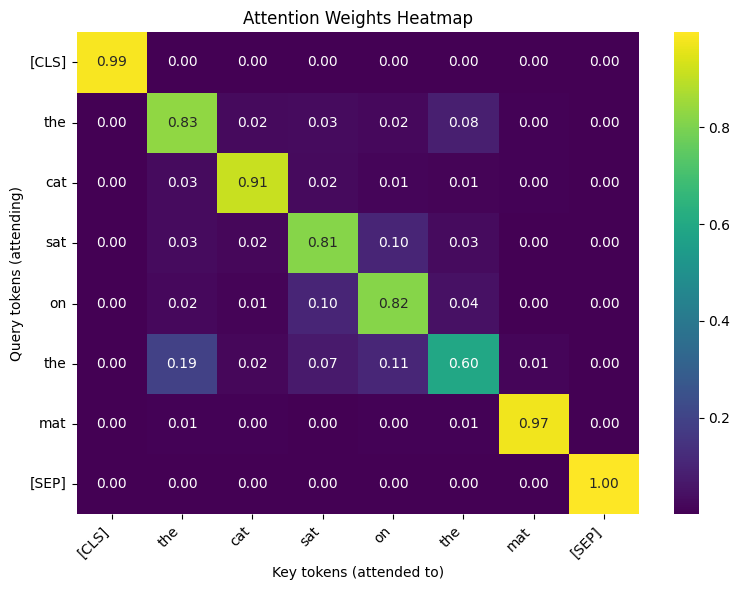

In [6]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import math
from transformers import AutoTokenizer, AutoModel


model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

sentence = "the cat sat on the mat"

# Tokenize
inputs = tokenizer(sentence, return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
seq_len = len(tokens)

# Get real embeddings from BERT
with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

embeddings = outputs.last_hidden_state[0]  # (seq_len, d_model=768)

# Treat embeddings as Q, K, V
# Add batch (1) and heads (1) dimensions
Q = embeddings.unsqueeze(0).unsqueeze(0) # Shape: (1, 1, seq_len, d_model)
K = embeddings.unsqueeze(0).unsqueeze(0) # Shape: (1, 1, seq_len, d_model)
V = embeddings.unsqueeze(0).unsqueeze(0) # Shape: (1, 1, seq_len, d_model)



# Compute Scaled Dot-Product Attention

output, attention_weights = scaled_dot_product_attention(Q, K, V)  # Correctly unpack the tuple

# Extract single head attention weights for visualization
weights_to_plot = attention_weights[0, 0].detach().numpy()  # (seq_len_q, seq_len_k)

# Plot attention heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    weights_to_plot,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="viridis",
    annot=True,
    fmt=".2f"
)

plt.title("Attention Weights Heatmap")
plt.xlabel("Key tokens (attended to)")
plt.ylabel("Query tokens (attending)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### **Task 2.3 Experiments (15 points)**

**Experiment 1 — Change One Word:**

1. Use a simple sentence, for example:
    the cat sat on the mat
2. Compute and plot the attention weights as a heatmap.
3. Change one word in the sentence, for example:
    the dog sat on the mat
4. Recompute and plot the attention heatmap.
5. Compare the two heatmaps and explain whether the attention pattern changed.

**Experiment 2 — Compare Different Attention Heads:**

Repeat the attention visualization using at least two different attention heads.

For each head, create separate projection matrices:

$$W_Q, W_K, W_V$$

Use them to compute:
$$Q=XW_Q, K=XW_K, V=XW_V$$

Then compute and plot the attention weights for each head.

**Questions**

Answer briefly:

1. Did changing one word affect the attention weights? Why or why not?
2. Do different attention heads focus on different tokens?
3. Why might multi-head attention be useful in Transformer models?

## Experiment 1

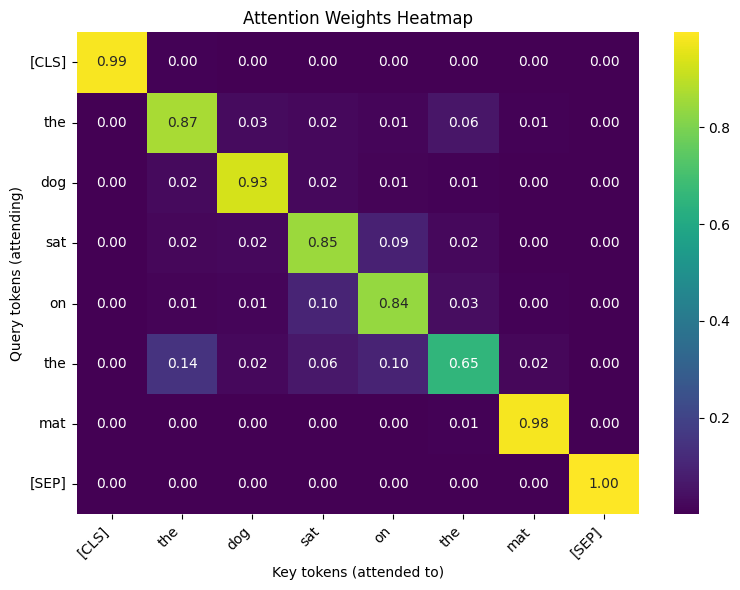

In [16]:


from transformers import AutoTokenizer, AutoModel
import torch

model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

sentence = "the dog sat on the mat"

# Tokenize
inputs = tokenizer(sentence, return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
seq_len = len(tokens)

# Get real embeddings from BERT
with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

embeddings = outputs.last_hidden_state[0]  # (seq_len, d_model=768)

# Treat embeddings as Q, K, V
# Add batch (1) and heads (1) dimensions
Q = embeddings.unsqueeze(0).unsqueeze(0) # Shape: (1, 1, seq_len, d_model)
K = embeddings.unsqueeze(0).unsqueeze(0) # Shape: (1, 1, seq_len, d_model)
V = embeddings.unsqueeze(0).unsqueeze(0) # Shape: (1, 1, seq_len, d_model)


# Compute Scaled Dot-Product Attention

output, attention_weights = scaled_dot_product_attention(Q, K, V)  # Correctly unpack the tuple

# Extract single head attention weights for visualization
weights_to_plot = attention_weights[0, 0].detach().numpy()  # (seq_len_q, seq_len_k)

# Plot attention heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    weights_to_plot,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="viridis",
    annot=True,
    fmt=".2f"
)

plt.title("Attention Weights Heatmap")
plt.xlabel("Key tokens (attended to)")
plt.ylabel("Query tokens (attending)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Experiment 2

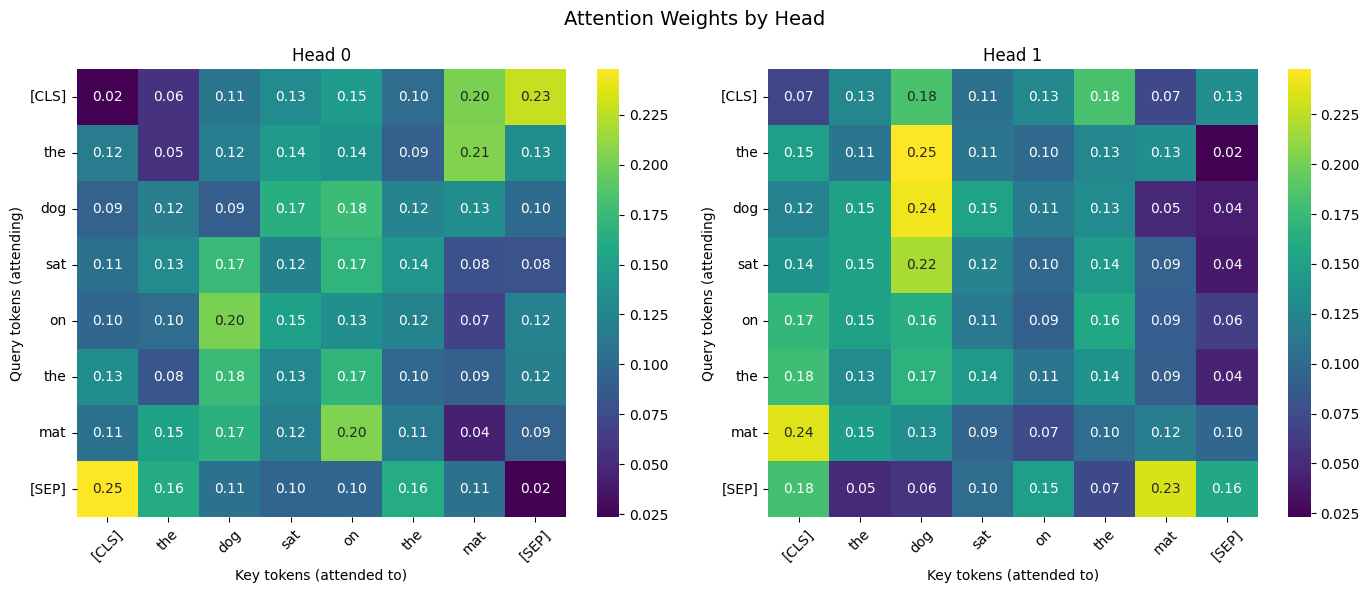

In [15]:
num_heads = 2
d_model = 768
d_k = d_model // num_heads

bert_attention = model.encoder.layer[0].attention.self

W_q = bert_attention.query.weight.T   # (768, 768)
W_k = bert_attention.key.weight.T     # (768, 768)
W_v = bert_attention.value.weight.T   # (768, 768)


Q = (embeddings @ W_q).view(seq_len, num_heads, d_k).transpose(0, 1).unsqueeze(0)  # (1, 2, seq_len, 384)
K = (embeddings @ W_k).view(seq_len, num_heads, d_k).transpose(0, 1).unsqueeze(0)  # (1, 2, seq_len, 384)
V = (embeddings @ W_v).view(seq_len, num_heads, d_k).transpose(0, 1).unsqueeze(0)  # (1, 2, seq_len, 384)

output, attention_weights = scaled_dot_product_attention(Q, K, V)

# Plot both heads side by side
fig, axes = plt.subplots(1, num_heads, figsize=(14, 6))
for head in range(num_heads):
    weights_to_plot = attention_weights[0, head].detach().numpy()  # (seq_len, seq_len)
    sns.heatmap(
        weights_to_plot,
        ax=axes[head],
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="viridis",
        annot=True,
        fmt=".2f"
    )
    axes[head].set_title(f"Head {head}")
    axes[head].set_xlabel("Key tokens (attended to)")
    axes[head].set_ylabel("Query tokens (attending)")
    axes[head].tick_params(axis='x', rotation=45)
    axes[head].tick_params(axis='y', rotation=0)

plt.suptitle("Attention Weights by Head", fontsize=14)
plt.tight_layout()
plt.show()


## Answers
1. Did changing one word affect the attention weights? Why or why not?

Yes it slightly changed the weights and it makmes sense since dog has a different semantic meaning than cat

2. Do different attention heads focus on different tokens?
Yes we can see that the attention maps look different for the two heads

3. Why might multi-head attention be useful in Transformer models?
Because it allows the model to jointly attend to information from different representation subspaces simultaneously. A single attention head is forced to summarize all relationships into one weighted average — it can only capture one type of pattern at a time. With multiple heads, each head can specialize.